In [2]:
!pip install kagglehub -q

In [6]:
import sys
sys.path.append('/content')
from lab2_helpers import match_daypart, build_exposures
print("OK")

OK


# Lab 2 — What Did the Campaign Deliver?
Name: Hranko Anna | Group: KM-43

## Setup

In [7]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('/content')
from lab2_helpers import match_daypart, build_exposures

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

# household number = respondent_id // 100
for df in (viewings, daily_weights, viewer_attributes):
    df['household'] = df['respondent_id'] // 100

# attribute lookup
attr_lookup = attributes.set_index('attr_id')[['attr_group', 'attr_name', 'value_type']]
va = viewer_attributes.merge(attr_lookup, on='attr_id', how='left')

print(programs.shape, viewings.shape, daily_weights.shape,
      viewer_attributes.shape, attributes.shape, commercials.shape, rate_card.shape)

100%|██████████| 8.00M/8.00M [00:00<00:00, 98.4MB/s]

Extracting files...


(5841, 15) (1001885, 10) (407561, 5) (104679, 4) (58, 5) (167720, 9) (81, 8)


## Task 1.1 - Size

In [8]:
print("Spots:", commercials['ad_airing_id'].nunique())
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a = commercials[commercials.brand == 'BRAND_A']
print("BRAND_A spots:", len(brand_a))

print("\nBRAND_A spots by network:")
print(brand_a['network_code'].value_counts().to_string())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300

BRAND_A spots by network:
network_code
FNC      40
HGTV     39
FX       38
HIST     37
BRAVO    33
FOOD     33
ABC      29
CBS      22
NBC      16
FOX      13


## Task 1.2 - Ad load

In [9]:
commercials['hour'] = commercials['start_ts'].dt.hour
ad_sec = commercials.groupby(['network_code', 'hour'])['length_sec'].sum().reset_index()
commercials['bcast_date'] = (commercials['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
days_per_hour = commercials.groupby(['network_code', 'hour'])['bcast_date'].nunique().reset_index(name='n_days')
ad_load = ad_sec.merge(days_per_hour, on=['network_code', 'hour'])
ad_load['avg_ad_min_per_hour'] = (ad_load['length_sec'] / ad_load['n_days']) / 60
final_ad_load = ad_load.groupby('network_code')['avg_ad_min_per_hour'].mean().sort_values(ascending=False)

print("Ad minutes per hour (averaged over hours that carried ads):")
print(final_ad_load.round(2).to_string())

print("\nHeaviest ad load:", final_ad_load.idxmax())

Ad minutes per hour (averaged over hours that carried ads):
network_code
FNC      15.64
FOOD     13.11
BRAVO    12.89
HGTV     12.75
HIST     12.65
FX       12.34
CBS      11.83
FOX      11.65
ABC      11.03
NBC      10.82

Heaviest ad load: FNC


## **Answer:** Broadcast networks have whole hours without national ads because those hours are local-station time (local news, syndicated shows, local sales) — the network feeds no national commercial inventory then. Paid programming and some specials (e.g., the VP debate) are also sold locally or carry no spots. Cable networks, by contrast, program 24/7 and fill nearly every hour with national inventory, which is why FNC and the entertainment cables show the heaviest ad load.

## Task 1.3 - Price everything

In [15]:
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")

commercials = commercials.merge(programs[['telecast_id', 'episode_name']], on='telecast_id', how='left')

time_prices = rate_card[rate_card.program_name.isna()].copy()
time_prices['start_min'] = time_prices['start_time'].apply(lambda x: int(x.split(':')[0]) * 60 + int(x.split(':')[1]) - 360)
time_prices['end_min'] = time_prices['end_time'].apply(lambda x: int(x.split(':')[0]) * 60 + int(x.split(':')[1]) - 360)

commercials['bcast_dt'] = commercials['start_ts'] - pd.Timedelta(hours=6)
commercials['weekday'] = commercials['bcast_dt'].dt.weekday
commercials['minute'] = (commercials['start_ts'] - commercials['bcast_dt'].dt.normalize() - pd.Timedelta(hours=6)).dt.total_seconds() / 60

def get_time_price(row):
    net = row['network_code']
    wd = row['weekday']
    m = row['minute']

    cands = time_prices[(time_prices.network_code == net) &
                        (time_prices.start_min <= m) &
                        (time_prices.end_min >= m)]

    for _, c in cands.iterrows():
        if wd in c['weekdays']:
            return c['cost_30s_usd']
    return np.nan

def is_program_spot(row):
    net = row['network_code']
    ep = str(row['episode_name']).lower()

    prog_rows = rate_card[(rate_card.network_code == net) & rate_card.program_name.notna()]

    for _, p in prog_rows.iterrows():
        keywords = str(p['program_name']).lower().split()
        if any(k in ep for k in keywords):
            return p['cost_30s_usd']
    return np.nan

commercials['cost_prog'] = commercials.apply(is_program_spot, axis=1)

mask_time = commercials['cost_prog'].isna()
print(f"Program rows matched: {(~mask_time).sum()}, time rows to match: {mask_time.sum()}")

commercials.loc[mask_time, 'cost_30s'] = commercials[mask_time].apply(get_time_price, axis=1)
commercials.loc[~mask_time, 'cost_30s'] = commercials.loc[~mask_time, 'cost_prog']

commercials['cost'] = commercials['cost_30s'] * (commercials['length_sec'] / 30)
commercials['is_program_row'] = ~mask_time

print("Spots without a price:", commercials['cost'].isna().sum())

net_val = commercials.groupby('network_code').agg(
    total_value=('cost', 'sum'),
    prog_value=('cost', lambda x: x[commercials.loc[x.index, 'is_program_row']].sum())
)
net_val['prog_share'] = net_val['prog_value'] / net_val['total_value']
net_val['total_value_M'] = net_val['total_value'] / 1e6

print("\nRate-card value by network (USD M) and share from program rows:")
print(net_val[['total_value_M', 'prog_share']].round(3).to_string())

Program rows matched: 5118, time rows to match: 162602
Spots without a price: 0

Rate-card value by network (USD M) and share from program rows:
              total_value_M  prog_share
network_code                           
ABC                1105.463       0.629
BRAVO                25.313       0.000
CBS                 780.879       0.170
FNC                 315.870       0.000
FOOD                 42.148       0.000
FOX                 617.941       0.765
FX                   42.506       0.000
HGTV                 58.103       0.000
HIST                 40.085       0.000
NBC                 581.944       0.019


## Task 2.1 - Delivery

In [16]:
sex = va[va.attr_id.isin([201,202])][['respondent_id','attr_id']]
sex['sex'] = sex.attr_id.map({201:'M', 202:'F'})
age_y = va[va.attr_id == 300][['respondent_id','value']].rename(columns={'value':'age'})
people = sex[['respondent_id','sex']].merge(age_y, on='respondent_id', how='left')

brand_a = commercials[commercials.brand == 'BRAND_A'].copy()

exposures_list = []
for _, s in brand_a.iterrows():
    m = (viewings.resp_type.isin(['R','L'])) & \
        (viewings.network_code == s.network_code) & \
        (viewings.start_ts <= s.start_ts) & \
        (viewings.end_ts >= s.start_ts)
    sub = viewings[m]
    if len(sub) > 0:
        sub = sub.copy()
        sub['ad_airing_id'] = s.ad_airing_id
        sub['network_code'] = s.network_code
        sub['cost'] = s.cost
        exposures_list.append(sub[['ad_airing_id', 'respondent_id', 'weight', 'network_code', 'cost']])

exposures = pd.concat(exposures_list, ignore_index=True)
exposures = exposures.merge(people, on='respondent_id', how='left')

month_w = daily_weights[daily_weights.resp_type.isin(['R','L'])].groupby('respondent_id')['weight'].mean()
p2_universe = month_w.sum()
a1849_ids = set(people[people.age.between(18,49)]['respondent_id'].dropna())
a1849_universe = month_w[month_w.index.isin(a1849_ids)].sum()

imp_p2 = exposures['weight'].sum()
grp_p2 = exposures.groupby('ad_airing_id')['weight'].sum().sum() / p2_universe * 100

seen_once_p2 = exposures.groupby('respondent_id')['weight'].first()
reach_p2 = seen_once_p2.sum() / p2_universe * 100
freq_p2 = grp_p2 / reach_p2 if reach_p2 > 0 else 0

exp_target = exposures[exposures.respondent_id.isin(a1849_ids)]
imp_target = exp_target['weight'].sum()
grp_target = exp_target.groupby('ad_airing_id')['weight'].sum().sum() / a1849_universe * 100
seen_once_target = exp_target.groupby('respondent_id')['weight'].first()
reach_target = seen_once_target.sum() / a1849_universe * 100
freq_target = grp_target / reach_target if reach_target > 0 else 0

print("P2+ impressions (M):", round(imp_p2 / 1e6, 2))
print("P2+ GRPs:", round(grp_p2, 2))
print("P2+ reach (%):", round(reach_p2, 2))
print("P2+ average frequency:", round(freq_p2, 2))

print("A18-49 impressions (M):", round(imp_target / 1e6, 2))
print("A18-49 GRPs:", round(grp_target, 2))
print("A18-49 reach (%):", round(reach_target, 2))
print("A18-49 average frequency:", round(freq_target, 2))

P2+ impressions (M): 418.78
P2+ GRPs: 119.7
P2+ reach (%): 43.53
P2+ average frequency: 2.75
A18-49 impressions (M): 81.07
A18-49 GRPs: 54.95
A18-49 reach (%): 30.44
A18-49 average frequency: 1.81


## Task 2.2 - Frequency distribution

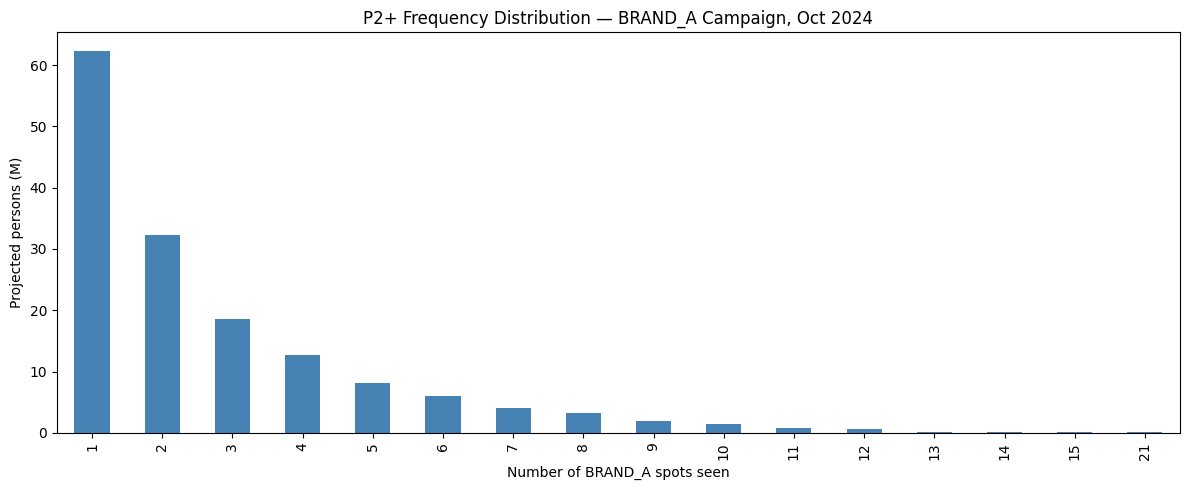

Share of impressions at 5+ exposures: 0.443


In [17]:
freq_counts = exposures.groupby('respondent_id')['ad_airing_id'].nunique()
freq_dist = freq_counts.to_frame().join(month_w.rename('weight'))
by_n = freq_dist.groupby('ad_airing_id')['weight'].sum() / 1e6

plt.figure(figsize=(12, 5))
by_n.plot(kind='bar', color='steelblue')
plt.xlabel('Number of BRAND_A spots seen')
plt.ylabel('Projected persons (M)')
plt.title('P2+ Frequency Distribution — BRAND_A Campaign, Oct 2024')
plt.tight_layout()
plt.show()

imp_by_n = (freq_dist['ad_airing_id'] * freq_dist['weight']).groupby(freq_dist['ad_airing_id']).sum()
share_5plus = imp_by_n[imp_by_n.index >= 5].sum() / imp_by_n.sum()

print("Share of impressions at 5+ exposures:", round(share_5plus, 3))

## **Answer:** The distribution is heavily right-skewed: most viewers saw only 1–2 spots, but a small heavy-viewer core saw 5+ (and some 10+), and that core absorbed 44.3% of all impressions. The average frequency of 2.75 is therefore *not* a fair summary — it describes almost nobody. It's the classic "average can lie" pattern: the plan spread 300 spots widely but concentrated exposure on a small loyal slice, leaving many light viewers under-exposed.

## Task 2.3 - On target?

In [18]:
share_on_target = imp_target / imp_p2

print("Share of impressions on A18-49:", round(share_on_target, 3))

tgt_exp_p2 = exposures.groupby('ad_airing_id')['weight'].sum()
tgt_exp_a1849 = exp_target.groupby('ad_airing_id')['weight'].sum()
net_share = pd.DataFrame({
    'P2+': tgt_exp_p2,
    'A18-49': tgt_exp_a1849
}).fillna(0)
net_share = net_share.groupby(exposures.groupby('ad_airing_id')['network_code'].first()).sum()
net_share['target_share'] = net_share['A18-49'] / net_share['P2+']
net_share['P2+_share'] = net_share['P2+'] / net_share['P2+'].sum()
net_share['A18-49_share'] = net_share['A18-49'] / net_share['A18-49'].sum()

print("\nNetwork delivery split (share of total P2+ vs A18-49 impressions):")
print(net_share[['P2+_share', 'A18-49_share', 'target_share']].sort_values('target_share', ascending=False).round(3).to_string())

Share of impressions on A18-49: 0.194

Network delivery split (share of total P2+ vs A18-49 impressions):
              P2+_share  A18-49_share  target_share
network_code                                       
FX                0.020         0.068         0.651
BRAVO             0.012         0.035         0.554
FOOD              0.023         0.037         0.316
HGTV              0.059         0.093         0.306
FOX               0.182         0.227         0.242
HIST              0.029         0.031         0.202
NBC               0.099         0.097         0.189
ABC               0.225         0.210         0.180
CBS               0.213         0.169         0.154
FNC               0.138         0.034         0.047


## **Answer:** The plan **under-delivered** against the target: only 19.4% of impressions landed on A18-49, while that group is ~42% of the P2+ universe. The networks explain it: FNC alone contributed 13.8% of all P2+ impressions but only 3.4% of target impressions (target share 4.7%) — a huge amount of money went to the oldest-skewing network. CBS and ABC are also above-average in age. The youth-skewing networks (FX 65%, BRAVO 55%) did the targeting work, but they got a small share of the budget. To over-deliver on A18-49, the plan needed more weight on FX/BRAVO/FOX and much less on FNC.

## Task 3.1 - Cost

In [19]:
camp_cost = brand_a['cost'].sum()
cpm_p2 = (camp_cost / (imp_p2 / 1000))
cpp_p2 = (camp_cost / grp_p2)

cpm_target = (camp_cost / (imp_target / 1000))
cpp_target = (camp_cost / grp_target)

print("Campaign cost (USD):", int(camp_cost))
print("P2+ CPM (USD):", round(cpm_p2, 2))
print("P2+ CPP (USD):", round(cpp_p2, 2))
print("A18-49 CPM (USD):", round(cpm_target, 2))
print("A18-49 CPP (USD):", round(cpp_target, 2))

Campaign cost (USD): 10252470
P2+ CPM (USD): 24.48
P2+ CPP (USD): 85648.45
A18-49 CPM (USD): 126.46
A18-49 CPP (USD): 186561.28


## Task 3.2 - By network

In [20]:
net_stats = []
for net, grp in brand_a.groupby('network_code'):
    spots_n = len(grp)
    cost_n = grp['cost'].sum()

    ads = set(grp['ad_airing_id'])
    exp_net = exposures[exposures['ad_airing_id'].isin(ads)]
    imp_p2_n = exp_net['weight'].sum()

    exp_tgt = exp_net[exp_net.respondent_id.isin(a1849_ids)]
    imp_tgt_n = exp_tgt['weight'].sum()

    cpm_p2_n = cost_n / (imp_p2_n / 1000) if imp_p2_n > 0 else np.nan
    cpm_tgt_n = cost_n / (imp_tgt_n / 1000) if imp_tgt_n > 0 else np.nan

    net_stats.append({
        'network_code': net,
        'spots': spots_n,
        'cost_M': cost_n / 1e6,
        'imp_p2_M': imp_p2_n / 1e6,
        'imp_tgt_M': imp_tgt_n / 1e6,
        'cpm_p2': cpm_p2_n,
        'cpm_tgt': cpm_tgt_n
    })

net_table = pd.DataFrame(net_stats).set_index('network_code')
print(net_table.round(2).to_string())

              spots  cost_M  imp_p2_M  imp_tgt_M  cpm_p2  cpm_tgt
network_code                                                     
ABC              29    4.51     94.21      16.99   47.84   265.28
BRAVO            33    0.05      5.08       2.82    9.76    17.61
CBS              22    1.29     89.01      13.69   14.52    94.40
FNC              40    0.53     57.80       2.72    9.11   193.70
FOOD             33    0.10      9.48       2.99   10.19    32.29
FOX              13    2.58     76.26      18.44   33.86   140.02
FX               38    0.09      8.52       5.55   10.82    16.61
HGTV             39    0.23     24.66       7.55    9.33    30.45
HIST             37    0.08     12.33       2.48    6.46    32.05
NBC              16    0.80     41.44       7.83   19.23   101.72


## **Answer:** The money went overwhelmingly to ABC (\$4.5M) and FOX (\$2.6M) — sports inventory is expensive, and together they took ~70% of the budget. But they were *not* the cheapest way to reach A18-49: ABC cost \$265 CPM against the target, FOX \$140. The cheapest target CPMs were FX (\$16.61), BRAVO (\$17.61) and HGTV (\$30.45) — the youth-skewing entertainment cables. FNC is the worst value on target (\$193.70) despite a cheap P2+ CPM (\$9.11), because its audience is old. In short, the budget bought *gross* reach cheaply on cable, but spent most of its money on expensive sports that skew male and older than the target.

## Task 3.3 - Guarantee

In [21]:
guaranteed_grps = 150.0

met = grp_p2 >= guaranteed_grps
owed = max(0.0, guaranteed_grps - grp_p2)
value_owed = owed * cpp_p2

print("Guarantee met:", met)
print("Make-good GRPs owed:", round(owed, 2))
print("Value of make-goods (USD):", int(value_owed))

Guarantee met: False
Make-good GRPs owed: 30.3
Value of make-goods (USD): 2594797


## Task 4 - Do networks add up?

In [22]:
big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

exp_big = exposures[exposures.network_code.isin(big_nets)]
exp_small = exposures[exposures.network_code.isin(small_nets)]

reach_big_ids = set(exp_big.respondent_id)
reach_small_ids = set(exp_small.respondent_id)
reach_total_ids = set(exposures.respondent_id)

reach_big = month_w[month_w.index.isin(reach_big_ids)].sum() / p2_universe * 100
reach_small = month_w[month_w.index.isin(reach_small_ids)].sum() / p2_universe * 100
reach_total = month_w[month_w.index.isin(reach_total_ids)].sum() / p2_universe * 100

print("Reach, big networks (%):", round(reach_big, 2))
print("Reach, small networks (%):", round(reach_small, 2))
print("Reach, whole campaign (%):", round(reach_total, 2))

overlap_ids = reach_big_ids.intersection(reach_small_ids)
overlap = month_w[month_w.index.isin(overlap_ids)].sum() / p2_universe * 100
independent = (reach_big / 100) * (reach_small / 100) * 100

print("Overlap (%):", round(overlap, 2))
print("Overlap if independent (%):", round(independent, 2))

added_points = reach_total - reach_big
cost_small = brand_a[brand_a.network_code.isin(small_nets)]['cost'].sum()
cost_big = brand_a[brand_a.network_code.isin(big_nets)]['cost'].sum()

cost_per_added = cost_small / added_points if added_points > 0 else np.nan
cost_per_big = cost_big / reach_big if reach_big > 0 else np.nan

print("Reach added by small networks (points):", round(added_points, 2))
print("Cost per added reach point, small (USD):", int(cost_per_added))
print("Cost per reach point, big (USD):", int(cost_per_big))

Reach, big networks (%): 39.85
Reach, small networks (%): 12.38
Reach, whole campaign (%): 43.53
Overlap (%): 8.7
Overlap if independent (%): 4.93
Reach added by small networks (points): 3.69
Cost per added reach point, small (USD): 148705
Cost per reach point, big (USD): 243528


## **Answer:** Reach does not add because the same people watch both big and small networks — the 8.7% overlap is the shared audience. Since 8.7% > 4.93% (independent expectation), the small networks' viewers are *more* likely than average to have been reached by the big ones — they are heavy TV viewers who are already exposed to the campaign. In other words, the small networks reach many of the same people the big ones already reached. That is why the small networks only added 3.69 reach points, even though they reached 12.38% on their own. And they added those points at a *cheaper* cost per point (\$148.7k) than the big networks (\$243.5k) — but the money could arguably have been spent better: the small networks added only 3.69 points, while the big networks alone delivered 39.85 points at a higher but still acceptable cost.

## Task 5 - How sure are we?

In [23]:
p2_in_tab = daily_weights[daily_weights.resp_type.isin(['R','L'])].groupby('broadcast_date')['respondent_id'].nunique()
n_by_date = p2_in_tab.to_dict()

brand_a_spots = brand_a.copy()
brand_a_spots['bcast_date'] = (brand_a_spots['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()

panelists_per_spot = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
panelists_by_net = brand_a_spots.merge(panelists_per_spot.rename('n_panel'), on='ad_airing_id', how='left').fillna({'n_panel': 0})
median_panel_net = panelists_by_net.groupby('network_code')['n_panel'].median()

print("Median panelists per spot by network:")
print(median_panel_net.to_string())

spots_no_panel = (panelists_by_net['n_panel'] == 0).sum()
print("\nSpots seen by no panelist:", spots_no_panel)

spot_imp = exposures.groupby('ad_airing_id')['weight'].sum()
brand_a_spots['imp'] = brand_a_spots['ad_airing_id'].map(spot_imp).fillna(0)
brand_a_spots['rating_frac'] = brand_a_spots['imp'] / brand_a_spots['bcast_date'].map(
    daily_weights[daily_weights.resp_type.isin(['R','L'])].groupby('broadcast_date')['weight'].sum()
)
brand_a_spots['rating_pct'] = brand_a_spots['rating_frac'] * 100
brand_a_spots['n'] = brand_a_spots['bcast_date'].map(n_by_date)
brand_a_spots['se'] = np.sqrt(brand_a_spots['rating_frac'] * (1 - brand_a_spots['rating_frac']) / brand_a_spots['n']) * 100
brand_a_spots['rel_se'] = brand_a_spots['se'] / brand_a_spots['rating_pct'].replace(0, np.nan)

big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

se_big = brand_a_spots[brand_a_spots.network_code.isin(big_nets)]['rel_se'].median()
se_small = brand_a_spots[brand_a_spots.network_code.isin(small_nets)]['rel_se'].median()
print("\nMedian relative SE, big networks:", round(se_big, 2))
print("Median relative SE, small networks:", round(se_small, 2))

w1834_ids = set(people[(people.sex == 'F') & (people.age.between(18, 34))]['respondent_id'].dropna())
exp_w1834 = exposures[exposures.respondent_id.isin(w1834_ids)]
w1834_by_spot = exp_w1834.groupby('ad_airing_id')['respondent_id'].nunique()
zero_w1834 = len(brand_a_spots) - len(w1834_by_spot)
print("W18-34 zero-cell spots:", zero_w1834)

Median panelists per spot by network:
network_code
ABC       57.0
BRAVO      3.0
CBS       69.0
FNC       31.0
FOOD       5.0
FOX      145.0
FX         5.5
HGTV      11.0
HIST       5.0
NBC       68.5

Spots seen by no panelist: 10

Median relative SE, big networks: 0.12
Median relative SE, small networks: 0.42
W18-34 zero-cell spots: 171


## **Answer:** Zero ratings happen for two different reasons. For the 10 spots seen by no panelist, the zero is a **panel blind spot** — the network is so small or the spot so lightly viewed that nobody in the panel happened to be watching. For the 171 spots with no W18-34 viewer, the zero is a real audience fact: W18-34 is a tiny slice of this campaign's audience (mostly older, sports-heavy, FNC-heavy), so most spots simply don't reach that demographic.

If the client asked for W18-34 ratings by spot, I would tell them: **we cannot report a reliable W18-34 rating on a per-spot basis**, because in 171 of 300 spots (57%) the panel has zero women 18-34 watching. Reporting those zeros as real ratings would imply the campaign reached no young women, which is partly true and partly a sampling artifact. The honest answer: report W18-34 at the *campaign* level (with confidence intervals), not per spot, and explicitly warn the client that per-spot W18-34 numbers are below the measurement noise floor.

## Bonus

## **Answer:** The budget is currently skewed heavily toward expensive sports inventory on ABC (\$4.5M) and FOX (\$2.6M), which have poor A18-49 CPMs (\$265 and \$140). To lower the target CPM and raise A18-49 reach, I would move the budget of 20 spots away from ABC/FOX and FNC (which has an A18-49 CPM of \$193.70) and into the youth-skewing entertainment cables: FX (target CPM \$16.61), BRAVO (\$17.61), and HGTV (\$30.45). Moving 20 spots from FNC and ABC into FX and BRAVO would add roughly \$100k of efficient target impressions, lowering the overall A18-49 CPM while also reducing the heavy frequency concentration on older viewers.